# Data Science — Project Phase 1: Data Preprocessing
**Hashemite University – Faculty of Engineering – Department of Computer Engineering**
Course: Data Science (2104081410) · Instructor: Dr. Mohammad Al-Hammouri · Fall 2026/2027

Dataset: `Project_dataset.csv` (customer data, 20,330 rows × 23 columns).

Pipeline: **load → explore → fix types/formats → standardize text → fix dates → remove duplicates → handle invalid values →
handle missing values → handle outliers → feature engineering → encoding → correlation/feature selection → scaling → export**.

## 0. Setup

In [1]:
import os, re
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA_PATH = os.path.join("data", "Project_dataset.csv")
FIG_DIR = os.path.join("outputs", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the data and first look

In [2]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()
print("Shape:", df.shape)
df.head()

Shape: (20330, 23)


,client_ref,client_name,sex,location,yearly_salary,spend_per_order,credit_rating_score,tenure_years,education,satisfaction_level,item_category,registration_date,birth_date,order_count,monthly_salary,satisfaction_points,account_status,previous_churn_flag,premium_customer,salary_bracket,web_session_ref,record_status,country_iso
0,CUST104028,Omar Khalil,Female,Madaba,44673.45,61.5,659.0,20.0,Bachelors,Low,FURNITURE,5/11/2015,9/22/1966,44.0,3704.72,26.4,Yes,yes,No,Mid,S70341983,ACTIVE_RECORD,JO
1,CUST103875,Noor Martinez,Female,Beirut,NaN,163.13,552.0,18.0,Masters,Low,Groceries,11/25/2017,6/11/1999,27.0,3217.18,34.2,Yes,Yes,No,Unknown,S96145691,ACTIVE_RECORD,LB
2,CUST100140,Barbara Khalil,Female,Riyadh,47788.69,636.31,679.0,16.0,Masters,Medium,Clothing,28-Aug-24,8/23/1966,20.0,3997.06,50.8,No,No,Yes,Mid,S92821336,ACTIVE_RECORD,SA
3,CUST118494,Layla Davis,Female,Irbid,31224.97,124.99,652.0,0.0,Masters,Medium,Furniture,4/9/2020,7/11/1984,3.0,2579.47,54.6,Yes,Yes,No,Mid,S51977735,ACTIVE_RECORD,JO
4,CUST113071,Dina Brown,Male,Cairo,71332.65,1315.06,693.0,2.0,Bachelors,High,Clothing,9/1/2022,3/1/1987,8.0,5946.76,71.1,Yes,No,Yes,High,S31999955,ACTIVE_RECORD,EG


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20330 entries, 0 to 20329
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   client_ref           20330 non-null  str    
 1   client_name          20228 non-null  str    
 2   sex                  20330 non-null  str    
 3   location             19721 non-null  str    
 4   yearly_salary        19925 non-null  float64
 5   spend_per_order      20330 non-null  str    
 6   credit_rating_score  20031 non-null  float64
 7   tenure_years         19926 non-null  float64
 8   education            19519 non-null  str    
 9   satisfaction_level   19643 non-null  str    
 10  item_category        20330 non-null  str    
 11  registration_date    20330 non-null  str    
 12  birth_date           19925 non-null  str    
 13  order_count          19723 non-null  float64
 14  monthly_salary       20330 non-null  float64
 15  satisfaction_points  19719 non-null  float64
 1

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_ref,20330,20000,CUST116260,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
client_name,20228,1140,--,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,20330,8,Male,9715,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,19721,40,Amman,4658,NaN,NaN,NaN,NaN,NaN,NaN,NaN
yearly_salary,19925.0,NaN,NaN,NaN,42552.405986,37181.52665,5149.25,25944.3,36080.31,50598.08,1326768.671
spend_per_order,20330,17452,243.43,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_rating_score,20031.0,NaN,NaN,NaN,632.36144,178.203671,-999.0,608.0,649.0,690.0,999.0
tenure_years,19926.0,NaN,NaN,NaN,9.969688,6.039035,0.0,5.0,10.0,15.0,20.0
education,19519,16,Bachelors,7247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaction_level,19643,7,Medium,7698,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data quality assessment (before cleaning)

In [5]:
def quality_report(d):
    return pd.DataFrame({
        "dtype": d.dtypes.astype(str),
        "missing": d.isna().sum(),
        "missing_%": (d.isna().mean() * 100).round(2),
        "unique": d.nunique(),
    })

qr_before = quality_report(df)
print("Exact duplicate rows      :", df.duplicated().sum())
print("Duplicated client_ref IDs :", df["client_ref"].duplicated().sum())
qr_before

Exact duplicate rows      : 104
Duplicated client_ref IDs : 330


,dtype,missing,missing_%,unique
client_ref,str,0,0.00,20000
client_name,str,102,0.50,1140
sex,str,0,0.00,8
location,str,609,3.00,40
yearly_salary,float64,405,1.99,19567
spend_per_order,str,0,0.00,17452
credit_rating_score,float64,299,1.47,385
tenure_years,float64,404,1.99,21
education,str,811,3.99,16
satisfaction_level,str,687,3.38,7


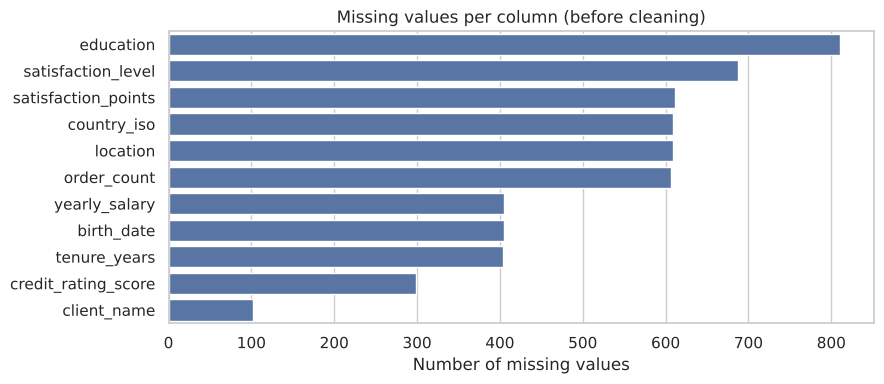

In [6]:
# Missing values per column (before)
miss = df.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]
plt.figure(figsize=(9, 4))
sns.barplot(x=miss.values, y=miss.index, color="#4C72B0")
plt.title("Missing values per column (before cleaning)")
plt.xlabel("Number of missing values"); plt.ylabel("")
savefig("01_missing_before.png")

In [7]:
# Inconsistent categories: the same value written in many ways
for col in ["sex", "education", "item_category", "satisfaction_level",
            "account_status", "previous_churn_flag"]:
    print(f"{col:20s} ->", df[col].value_counts(dropna=False).to_dict())

sex                  -> {'Male': 9715, 'Female': 9602, 'male': 192, 'MALE': 178, '  Female ': 165, '  Male ': 163, 'female': 161, 'FEMALE': 154}
education            -> {'Bachelors': 7247, 'High School': 6514, 'Masters': 3683, 'PhD': 902, nan: 811, '  Bachelors ': 159, 'BACHELORS': 159, 'high school': 152, 'bachelors': 146, 'HIGH SCHOOL': 142, '  High School ': 133, 'masters': 84, 'MASTERS': 73, '  Masters ': 72, '  PhD ': 20, 'PHD': 17, 'phd': 16}
item_category        -> {'Toys': 3274, 'Furniture': 3226, 'Electronics': 3218, 'Books': 3157, 'Clothing': 3156, 'Groceries': 3079, 'clothing': 94, '  Furniture ': 79, '  Toys ': 77, 'FURNITURE': 76, '  Groceries ': 75, 'CLOTHING': 72, 'furniture': 70, 'electronics': 68, 'TOYS': 68, 'GROCERIES': 67, '  Electronics ': 66, 'BOOKS': 64, 'books': 60, 'toys': 58, '  Clothing ': 57, '  Books ': 57, 'ELECTRONICS': 56, 'groceries': 56}
satisfaction_level   -> {'Medium': 7698, 'High': 5901, 'Low': 2920, 'Very High': 2026, 'Very Low': 978, nan: 687, '?

In [8]:
# Date formats found (digits replaced with 9)
for col in ["registration_date", "birth_date"]:
    pats = df[col].dropna().map(lambda s: re.sub(r"[A-Za-z]{3}", "Mon", re.sub(r"\d", "9", s)))
    print(col, pats.value_counts().to_dict())

registration_date {'9/99/9999': 9718, '9/9/9999': 4311, '99/99/9999': 3859, '99/9/9999': 1378, '99-Mon-99': 745, '9-Mon-99': 319}
birth_date {'9/99/9999': 10042, '9/9/9999': 4994, '99/99/9999': 3170, '99/9/9999': 1689, '9999-99-99': 30}


**Issues found:**
1. `spend_per_order` is text: some values have a `$` sign, thousands separators and spaces.
2. Text columns use different capitalisation and have extra spaces (`male`, `MALE`, `  Male `).
3. Yes/No columns are written in 10 ways (`Yes, yes, Y, 1, TRUE / No, no, N, 0, FALSE`).
4. Dates come in 4 formats (`m/d/Y`, `d/m/Y`, `dd-Mon-yy`, `Y-m-d`).
5. Placeholder values: `?` and `unknown` in `satisfaction_level`; `-999, -100, 0, 999` in `credit_rating_score`.
6. Duplicate rows, and the same customer stored more than once with small differences.
7. Missing values in 11 columns.
8. Outliers in `order_count` (values ×20 the normal range), `yearly_salary`, `monthly_salary`.
9. Columns with no useful information (`record_status` has one value; IDs and names).

## 3. Fix data types and standardize text

In [9]:
# 3.1 strip spaces from every text column; turn empty strings into NaN
obj_cols = df.select_dtypes(include=["object", "string"]).columns
for c in obj_cols:
    df[c] = df[c].str.strip().replace("", np.nan)

# 3.2 consistent capitalisation
df["client_name"]   = df["client_name"].str.title()
df["sex"]           = df["sex"].str.capitalize()
df["location"]      = df["location"].str.title()
df["item_category"] = df["item_category"].str.title()
df["country_iso"]   = df["country_iso"].str.upper()
edu_map = {"high school": "High School", "bachelors": "Bachelors", "masters": "Masters", "phd": "PhD"}
df["education"] = df["education"].str.lower().map(edu_map)

# 3.3 placeholder text -> NaN
df["satisfaction_level"] = df["satisfaction_level"].replace({"?": np.nan, "unknown": np.nan})
df["salary_bracket"]     = df["salary_bracket"].replace({"Unknown": np.nan})

# 3.4 unify boolean columns to 1 / 0
bool_map = {"yes": 1, "y": 1, "1": 1, "true": 1, "no": 0, "n": 0, "0": 0, "false": 0}
for c in ["account_status", "previous_churn_flag", "premium_customer"]:
    df[c] = df[c].astype(str).str.lower().map(bool_map).astype("Int64")

# 3.5 money text -> float
df["spend_per_order"] = pd.to_numeric(
    df["spend_per_order"].str.replace(r"[$,\s]", "", regex=True), errors="coerce")

for col in ["sex", "location", "education", "item_category", "satisfaction_level",
            "account_status", "previous_churn_flag", "premium_customer", "country_iso"]:
    print(f"{col:20s} ->", df[col].value_counts(dropna=False).to_dict())
print("spend_per_order dtype:", df["spend_per_order"].dtype, "| NaN:", df["spend_per_order"].isna().sum())

sex                  -> {'Male': 10248, 'Female': 10082}
location             -> {'Amman': 5078, 'Irbid': 2983, 'Zarqa': 2375, 'Cairo': 1889, 'Aqaba': 1582, 'Dubai': 1522, 'Salt': 1345, 'Riyadh': 1184, 'Madaba': 961, 'Beirut': 802, nan: 609}
education            -> {'Bachelors': 7711, 'High School': 6941, 'Masters': 3912, 'PhD': 955, nan: 811}
item_category        -> {'Toys': 3477, 'Furniture': 3451, 'Electronics': 3408, 'Clothing': 3379, 'Books': 3338, 'Groceries': 3277}
satisfaction_level   -> {'Medium': 7698, 'High': 5901, 'Low': 2920, 'Very High': 2026, 'Very Low': 978, nan: 807}
account_status       -> {np.int64(1): 14150, np.int64(0): 6180}
previous_churn_flag  -> {np.int64(0): 10232, np.int64(1): 10098}
premium_customer     -> {np.int64(0): 14231, np.int64(1): 6099}
country_iso          -> {'JO': 14324, 'EG': 1889, 'AE': 1522, 'SA': 1184, 'LB': 802, nan: 609}
spend_per_order dtype: float64 | NaN: 0


## 4. Parse dates (mixed formats)

In [10]:
def parse_date(s):
    """Parse the 4 date formats in this file. m/d/Y is the main format;
    when the first number is > 12 the value can only be d/m/Y."""
    if pd.isna(s):
        return pd.NaT
    s = str(s).strip()
    if re.fullmatch(r"\d{4}-\d{1,2}-\d{1,2}", s):
        return pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    if re.fullmatch(r"\d{1,2}-[A-Za-z]{3}-\d{2}", s):
        return pd.to_datetime(s, format="%d-%b-%y", errors="coerce")
    m = re.fullmatch(r"(\d{1,2})/(\d{1,2})/(\d{4})", s)
    if m:
        a = int(m.group(1))
        fmt = "%d/%m/%Y" if a > 12 else "%m/%d/%Y"
        return pd.to_datetime(s, format=fmt, errors="coerce")
    return pd.NaT

for c in ["registration_date", "birth_date"]:
    before_na = df[c].isna().sum()
    df[c] = df[c].map(parse_date)
    print(f"{c}: missing before = {before_na}, missing after parse = {df[c].isna().sum()}, "
          f"range = {df[c].min().date()} -> {df[c].max().date()}")

registration_date: missing before = 0, missing after parse = 0, range = 2015-01-01 -> 2024-12-30


birth_date: missing before = 405, missing after parse = 405, range = 1890-01-01 -> 2031-05-14


## 5. Remove duplicates

In [11]:
n0 = len(df)
df = df.drop_duplicates()
n1 = len(df)
# Same customer (client_ref) stored more than once, e.g. with a different web session.
# After standardizing the text these records are the same person -> keep the first one.
df = df.drop_duplicates(subset="client_ref", keep="first")
n2 = len(df)
print(f"Exact duplicate rows removed        : {n0 - n1}")
print(f"Repeated client_ref records removed : {n1 - n2}")
print(f"Rows left                           : {n2}")
assert df["client_ref"].is_unique

Exact duplicate rows removed        : 300
Repeated client_ref records removed : 30
Rows left                           : 20000


## 6. Handle invalid values (domain rules)

In [12]:
REF_DATE = pd.Timestamp("2024-12-31")   # last registration date in the data

# credit score must be in the FICO range 300..850; -999 / -100 / 0 / 999 are placeholders
bad_credit = ~df["credit_rating_score"].between(300, 850) & df["credit_rating_score"].notna()
print("Invalid credit scores ->", df.loc[bad_credit, "credit_rating_score"].value_counts().to_dict())
df.loc[bad_credit, "credit_rating_score"] = np.nan

# birth date: not in the future and customer at least 18 and at most 100 years old at REF_DATE
age = (REF_DATE - df["birth_date"]).dt.days / 365.25
bad_birth = df["birth_date"].notna() & ~age.between(18, 100)
print("Invalid birth dates (future / age < 18 / age > 100):", bad_birth.sum())
df.loc[bad_birth, "birth_date"] = pd.NaT

# order_count: normal values are 1..49; the large values are all multiples of 20 (data entry error)
bad_orders = df["order_count"] > 50
print("Invalid order_count values:", bad_orders.sum(),
      "| all multiples of 20:", bool((df.loc[bad_orders, "order_count"] % 20 == 0).all()))
df.loc[bad_orders, "order_count"] = np.nan

# satisfaction_points outside 0..100 ?
print("satisfaction_points outside 0..100:", (~df["satisfaction_points"].between(0, 100) & df["satisfaction_points"].notna()).sum())

Invalid credit scores -> {-999.0: 199, 999.0: 22, -100.0: 19, 0.0: 18}
Invalid birth dates (future / age < 18 / age > 100): 1166
Invalid order_count values: 77 | all multiples of 20: True
satisfaction_points outside 0..100: 0


## 7. Handle missing values

In [13]:
print(df.isna().sum()[df.isna().sum() > 0])

client_name              98
location                600
yearly_salary           400
credit_rating_score     556
tenure_years            400
education               798
satisfaction_level      796
birth_date             1564
order_count             676
satisfaction_points     599
salary_bracket          400
country_iso             600
dtype: int64


In [14]:
# 7.1 yearly_salary: monthly_salary is never missing and yearly = 12 x monthly (corr = 0.99999)
m = df["yearly_salary"].isna()
df.loc[m, "yearly_salary"] = df.loc[m, "monthly_salary"] * 12
print("yearly_salary filled from monthly_salary:", m.sum())

# 7.2 salary_bracket: recompute from salary using the bracket limits seen in the data
df["salary_bracket"] = pd.cut(df["yearly_salary"], bins=[0, 25000, 50000, 100000, np.inf],
                              labels=["Low", "Mid", "High", "Very High"], right=False).astype(str)

# 7.3 satisfaction_level <-> satisfaction_points are two forms of the same thing
sat_bins   = [-np.inf, 19, 39, 60, 80, np.inf]
sat_labels = ["Very Low", "Low", "Medium", "High", "Very High"]
print(df.groupby("satisfaction_level")["satisfaction_points"].agg(["min", "max", "mean"]).round(1))

m = df["satisfaction_level"].isna() & df["satisfaction_points"].notna()
df.loc[m, "satisfaction_level"] = pd.cut(df.loc[m, "satisfaction_points"], sat_bins, labels=sat_labels).astype(str)
print("satisfaction_level filled from points:", m.sum())

m = df["satisfaction_points"].isna() & df["satisfaction_level"].notna()
df.loc[m, "satisfaction_points"] = df.loc[m, "satisfaction_level"].map(
    df.groupby("satisfaction_level")["satisfaction_points"].median())
print("satisfaction_points filled with level median:", m.sum())

both = df["satisfaction_points"].isna()
df.loc[both, "satisfaction_points"] = df["satisfaction_points"].median()
df.loc[both, "satisfaction_level"] = df["satisfaction_level"].mode()[0]
print("both missing -> median / mode:", both.sum())

yearly_salary filled from monthly_salary: 400
                     min   max  mean
satisfaction_level                  
High                59.5  80.6  70.0
Low                 19.0  39.2  30.0
Medium              38.4  60.5  50.0
Very High           79.3  99.2  90.1
Very Low             0.2  18.7  10.0
satisfaction_level filled from points: 779
satisfaction_points filled with level median: 582
both missing -> median / mode: 17


In [15]:
# 7.4 numeric columns -> median (robust to outliers)
for c in ["credit_rating_score", "tenure_years", "order_count"]:
    n = df[c].isna().sum()
    df[c] = df[c].fillna(df[c].median())
    print(f"{c:20s} filled with median {df[c].median():.1f} ({n} values)")

# 7.5 birth_date -> median birth date
n = df["birth_date"].isna().sum()
df["birth_date"] = df["birth_date"].fillna(df["birth_date"].median())
print(f"birth_date filled with median date ({n} values)")

# 7.6 categorical columns
n = df["education"].isna().sum()
df["education"] = df["education"].fillna(df["education"].mode()[0])
print(f"education filled with mode '{df['education'].mode()[0]}' ({n} values)")

# location and country are missing together (same 609 rows) -> separate 'Unknown' category
n = df["location"].isna().sum()
df["location"] = df["location"].fillna("Unknown")
df["country_iso"] = df["country_iso"].fillna("Unknown")
print(f"location / country_iso filled with 'Unknown' ({n} values)")

# client_name is not used for modelling -> placeholder
df["client_name"] = df["client_name"].fillna("Unknown")

print("\nMissing values left:", int(df.isna().sum().sum()))

credit_rating_score  filled with median 649.5 (556 values)
tenure_years         filled with median 10.0 (400 values)
order_count          filled with median 25.0 (676 values)
birth_date filled with median date (1564 values)
education filled with mode 'Bachelors' (798 values)
location / country_iso filled with 'Unknown' (600 values)

Missing values left: 0


## 8. Handle outliers

                     IQR outliers   skew
yearly_salary               850.0  12.34
monthly_salary              852.0  12.34
spend_per_order             650.0   1.42
credit_rating_score         174.0   0.05
tenure_years                  0.0  -0.01
order_count                   0.0   0.01
satisfaction_points         712.0  -0.20


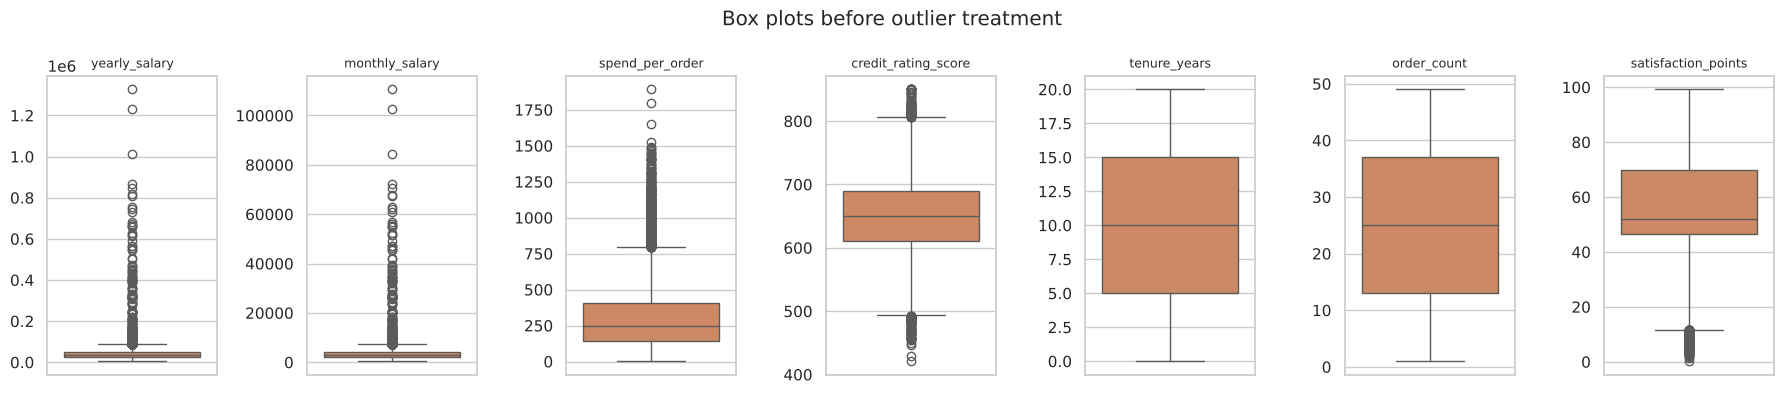

In [16]:
num_cols = ["yearly_salary", "monthly_salary", "spend_per_order", "credit_rating_score",
            "tenure_years", "order_count", "satisfaction_points"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print(pd.DataFrame({c: {"IQR outliers": iqr_outliers(df[c]),
                        "skew": round(df[c].skew(), 2)} for c in num_cols}).T)

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#DD8452"); ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.suptitle("Box plots before outlier treatment")
savefig("02_boxplots_before.png")

Capping limits: {'yearly_salary': (11160.91, 125603.76), 'monthly_salary': (931.8, 10480.87), 'spend_per_order': (22.75, 1010.43)}


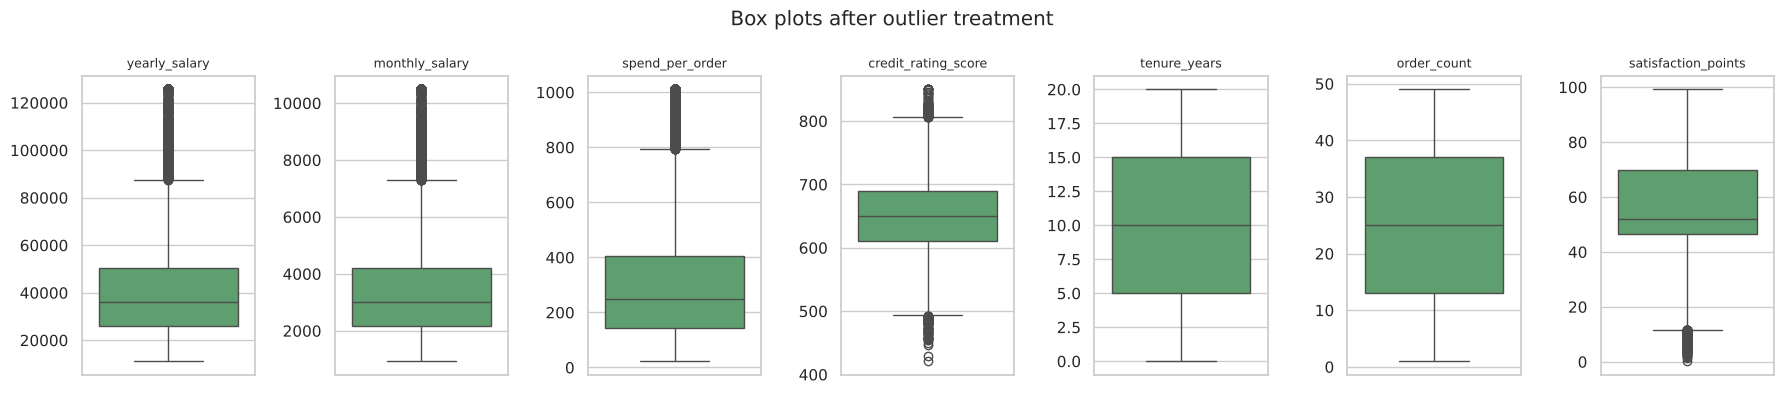

In [17]:
# Salaries and spend are right-skewed (real high earners, not errors: yearly = 12 x monthly still holds).
# Instead of deleting customers we cap (winsorize) at the 1st / 99th percentile.
caps = {}
for c in ["yearly_salary", "monthly_salary", "spend_per_order"]:
    lo, hi = df[c].quantile([0.01, 0.99])
    caps[c] = (round(lo, 2), round(hi, 2))
    df[c] = df[c].clip(lo, hi)
print("Capping limits:", caps)

fig, axes = plt.subplots(1, len(num_cols), figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#55A868"); ax.set_title(c, fontsize=9); ax.set_ylabel("")
plt.suptitle("Box plots after outlier treatment")
savefig("03_boxplots_after.png")

## 9. Feature engineering

In [18]:
df["age"] = ((REF_DATE - df["birth_date"]).dt.days / 365.25).round().astype(int)
df["registration_year"] = df["registration_date"].dt.year
df["days_since_registration"] = (REF_DATE - df["registration_date"]).dt.days
df["total_spend"] = (df["spend_per_order"] * df["order_count"]).round(2)
df["log_yearly_salary"] = np.log1p(df["yearly_salary"])

df[["age", "registration_year", "days_since_registration", "total_spend", "log_yearly_salary"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,20000.0,39.08,10.75,18.00,32.00,38.00,46.00,90.00
registration_year,20000.0,2019.51,2.86,2015.00,2017.00,2020.00,2022.00,2024.00
days_since_registration,20000.0,1822.21,1050.29,1.00,917.00,1822.00,2736.00,3652.00
total_spend,20000.0,7418.61,7193.45,22.75,2215.22,5253.98,10210.45,49510.89
log_yearly_salary,20000.0,10.50,0.50,9.32,10.16,10.49,10.83,11.74


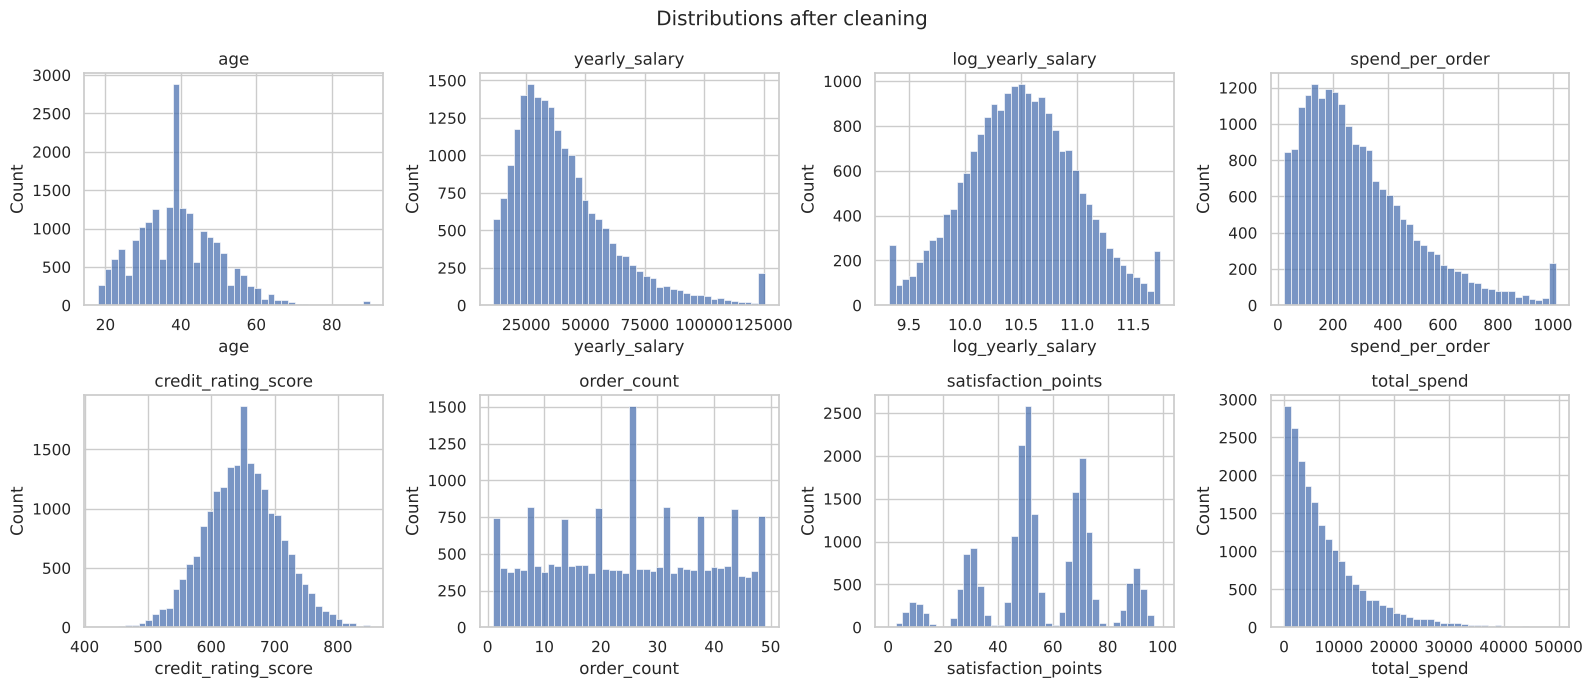

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), ["age", "yearly_salary", "log_yearly_salary", "spend_per_order",
                                "credit_rating_score", "order_count", "satisfaction_points", "total_spend"]):
    sns.histplot(df[c], bins=40, ax=ax, color="#4C72B0"); ax.set_title(c)
plt.suptitle("Distributions after cleaning")
savefig("04_distributions_after.png")

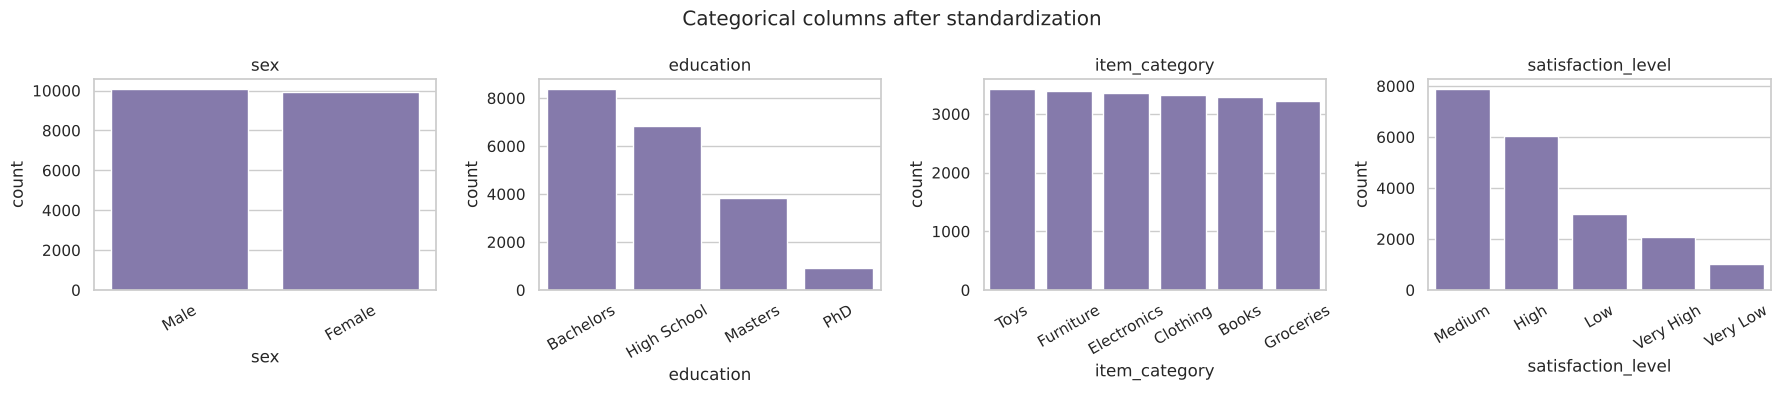

In [20]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, ["sex", "education", "item_category", "satisfaction_level"]):
    order = df[c].value_counts().index
    sns.countplot(x=df[c], order=order, ax=ax, color="#8172B3"); ax.set_title(c); ax.tick_params(axis="x", rotation=30)
plt.suptitle("Categorical columns after standardization")
savefig("05_categories_after.png")

## 10. Encoding categorical variables

In [21]:
clean = df.copy()   # human-readable cleaned dataset (saved later)

enc = df.copy()
# ordinal columns -> ordered integers
enc["education"]          = enc["education"].map({"High School": 0, "Bachelors": 1, "Masters": 2, "PhD": 3})
enc["satisfaction_level"] = enc["satisfaction_level"].map({"Very Low": 0, "Low": 1, "Medium": 2, "High": 3, "Very High": 4})
enc["salary_bracket"]     = enc["salary_bracket"].map({"Low": 0, "Mid": 1, "High": 2, "Very High": 3})
# binary
enc["sex"] = enc["sex"].map({"Male": 1, "Female": 0})
# nominal -> one-hot
enc = pd.get_dummies(enc, columns=["location", "item_category"], prefix=["loc", "cat"], dtype=int)
print("Encoded shape:", enc.shape)
enc.head()

Encoded shape: (20000, 43)


,client_ref,client_name,sex,yearly_salary,spend_per_order,credit_rating_score,tenure_years,education,satisfaction_level,registration_date,birth_date,order_count,monthly_salary,satisfaction_points,account_status,previous_churn_flag,premium_customer,salary_bracket,web_session_ref,record_status,...,days_since_registration,total_spend,log_yearly_salary,loc_Amman,loc_Aqaba,loc_Beirut,loc_Cairo,loc_Dubai,loc_Irbid,loc_Madaba,loc_Riyadh,loc_Salt,loc_Unknown,loc_Zarqa,cat_Books,cat_Clothing,cat_Electronics,cat_Furniture,cat_Groceries,cat_Toys
0,CUST104028,Omar Khalil,0,44673.45,61.5000,659.0,20.0,1,1,2015-05-11,1966-09-22,44.0,3704.72,26.4,1,1,0,1,S70341983,ACTIVE_RECORD,...,3522,2706.00,10.707157,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0
1,CUST103875,Noor Martinez,0,38606.16,163.1300,552.0,18.0,2,1,2017-11-25,1999-06-11,27.0,3217.18,34.2,1,1,0,1,S96145691,ACTIVE_RECORD,...,2593,4404.51,10.561193,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
2,CUST100140,Barbara Khalil,0,47788.69,636.3100,679.0,16.0,2,2,2024-08-28,1966-08-23,20.0,3997.06,50.8,0,0,1,1,S92821336,ACTIVE_RECORD,...,125,12726.20,10.774565,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0
3,CUST118494,Layla Davis,0,31224.97,124.9900,652.0,0.0,2,2,2020-04-09,1984-07-11,3.0,2579.47,54.6,1,1,0,1,S51977735,ACTIVE_RECORD,...,1727,374.97,10.349005,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
4,CUST113071,Dina Brown,1,71332.65,1010.4264,693.0,2.0,1,3,2022-09-01,1987-03-01,8.0,5946.76,71.1,1,0,1,2,S31999955,ACTIVE_RECORD,...,852,8083.41,11.175123,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0


## 11. Correlation analysis and feature selection

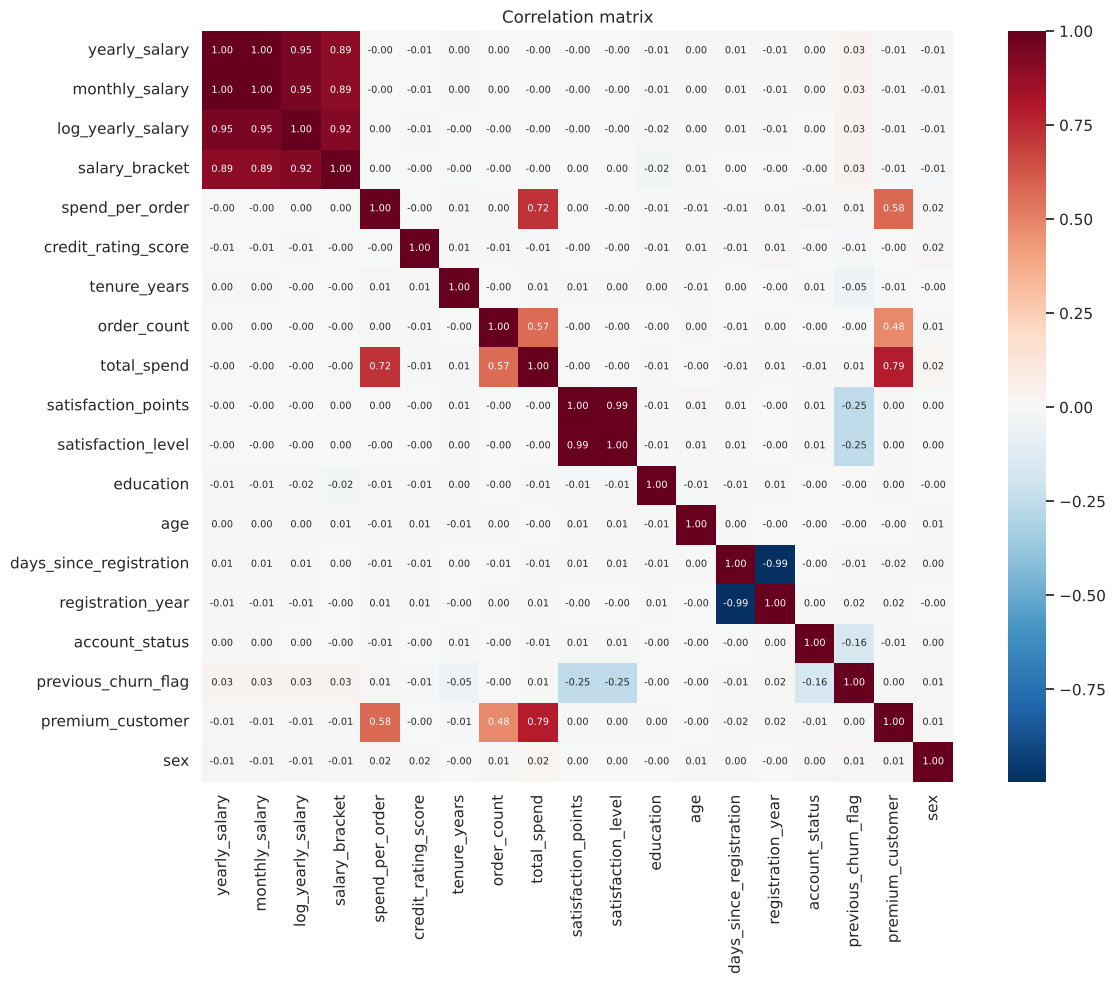

Highly correlated pairs (|r| > 0.85):
                level_0            level_1   corr
          yearly_salary     monthly_salary  1.000
days_since_registration  registration_year -0.995
    satisfaction_points satisfaction_level  0.989
          yearly_salary  log_yearly_salary  0.948
         monthly_salary  log_yearly_salary  0.948
      log_yearly_salary     salary_bracket  0.918
          yearly_salary     salary_bracket  0.892
         monthly_salary     salary_bracket  0.892


In [22]:
corr_cols = ["yearly_salary", "monthly_salary", "log_yearly_salary", "salary_bracket", "spend_per_order",
             "credit_rating_score", "tenure_years", "order_count", "total_spend", "satisfaction_points",
             "satisfaction_level", "education", "age", "days_since_registration", "registration_year",
             "account_status", "previous_churn_flag", "premium_customer", "sex"]
corr = enc[corr_cols].astype(float).corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True)
plt.title("Correlation matrix")
savefig("06_correlation.png")

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
         .rename("corr").reset_index().assign(abs=lambda d: d["corr"].abs())
         .sort_values("abs", ascending=False))
print("Highly correlated pairs (|r| > 0.85):")
print(pairs[pairs["abs"] > 0.85][["level_0", "level_1", "corr"]].round(3).to_string(index=False))

In [23]:
drop_cols = [
    "client_ref",          # ID only
    "client_name",         # personal identifier, no predictive value
    "web_session_ref",     # technical ID
    "record_status",       # constant (one value)
    "country_iso",         # fully determined by location
    "monthly_salary",      # = yearly_salary / 12 (r = 1.00)
    "yearly_salary",       # replaced by its log version
    "salary_bracket",      # binned copy of salary
    "satisfaction_level",  # binned copy of satisfaction_points
    "birth_date", "registration_date",   # replaced by age / days_since_registration
    "registration_year",   # same info as days_since_registration
]
print("Constant columns:", [c for c in raw.columns if raw[c].nunique() == 1])
model_df = enc.drop(columns=drop_cols)
print("Model-ready shape:", model_df.shape)
print(list(model_df.columns))

Constant columns: ['record_status']
Model-ready shape: (20000, 31)
['sex', 'spend_per_order', 'credit_rating_score', 'tenure_years', 'education', 'order_count', 'satisfaction_points', 'account_status', 'previous_churn_flag', 'premium_customer', 'age', 'days_since_registration', 'total_spend', 'log_yearly_salary', 'loc_Amman', 'loc_Aqaba', 'loc_Beirut', 'loc_Cairo', 'loc_Dubai', 'loc_Irbid', 'loc_Madaba', 'loc_Riyadh', 'loc_Salt', 'loc_Unknown', 'loc_Zarqa', 'cat_Books', 'cat_Clothing', 'cat_Electronics', 'cat_Furniture', 'cat_Groceries', 'cat_Toys']


## 12. Train / test split and feature scaling

In [24]:
# The scaler is fitted on the training set only, to avoid data leakage.
# previous_churn_flag is used as an example target for the next phase.
TARGET = "previous_churn_flag"
X = model_df.drop(columns=[TARGET])
y = model_df[TARGET].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scale_cols = ["log_yearly_salary", "spend_per_order", "credit_rating_score", "tenure_years",
              "order_count", "total_spend", "satisfaction_points", "education", "age",
              "days_since_registration"]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Target balance (train):", y_train.value_counts(normalize=True).round(3).to_dict())
X_train[scale_cols].describe().T[["mean", "std"]].round(3)

Train: (16000, 30) Test: (4000, 30)
Target balance (train): {0: 0.503, 1: 0.496}


,mean,std
log_yearly_salary,-0.0,1.0
spend_per_order,0.0,1.0
credit_rating_score,0.0,1.0
tenure_years,-0.0,1.0
order_count,0.0,1.0
total_spend,-0.0,1.0
satisfaction_points,0.0,1.0
education,-0.0,1.0
age,0.0,1.0
days_since_registration,-0.0,1.0


## 13. Summary and export

In [25]:
qr_after = quality_report(clean)
summary = pd.DataFrame({
    "Rows":            [len(raw), len(clean)],
    "Columns":         [raw.shape[1], clean.shape[1]],
    "Missing values":  [int(raw.isna().sum().sum()), int(clean.isna().sum().sum())],
    "Duplicate rows":  [int(raw.duplicated().sum()), int(clean.duplicated().sum())],
    "Duplicate IDs":   [int(raw["client_ref"].duplicated().sum()), int(clean["client_ref"].duplicated().sum())],
}, index=["Before", "After"]).T
print(summary)

out = "outputs"
clean.to_csv(os.path.join(out, "customers_cleaned.csv"), index=False)
model_df.to_csv(os.path.join(out, "customers_model_ready.csv"), index=False)
pd.concat([X_train, y_train], axis=1).to_csv(os.path.join(out, "train_scaled.csv"), index=False)
pd.concat([X_test, y_test], axis=1).to_csv(os.path.join(out, "test_scaled.csv"), index=False)
print("\nSaved files:", sorted(os.listdir(out)))

                Before  After
Rows             20330  20000
Columns             23     28
Missing values    5549      0
Duplicate rows     104      0
Duplicate IDs      330      0



Saved files: ['customers_cleaned.csv', 'customers_model_ready.csv', 'figures', 'test_scaled.csv', 'train_scaled.csv']
